# Get To Know A Dataset: Open Subsurface Data

This notebook is a guided tour of the [Open Subsurface Data](https://registry.opendata.aws/open-subsurface-data/) dataset (the registry page goes live at launch). More usage examples, tutorials and documentation for this dataset and others are on the [Registry of Open Data on AWS](https://registry.opendata.aws/).

The dataset holds open 3D post-stack seismic volumes gathered from public archives and the scientific ocean drilling data on Zenodo (LDEO LogDB downhole logs and the IODP community), kept exactly as the sources shipped them, with the tables that say what each file is, how to read the seismic headers and which Gulf of Mexico exploration wells sit inside each survey. Full documentation: [docs/dataset.md](https://github.com/mnky9800n/open-subsurface-data/blob/main/docs/dataset.md).

**Before launch.** The bucket does not exist yet. Set the environment variable `OSD_LOCAL_ROOT` to a folder laid out like the bucket and every cell reads from there instead. The same code runs against S3 once the bucket is up.

### Q: How have you organized your dataset? Help us understand the key prefix structure of your S3 bucket.

The bucket follows the layout in the AWS onboarding handbook (Appendix A). Source files and the files we wrote never share a prefix.

```
s3://veleslabs-open-subsurface-data/
  README.txt                        what the dataset is, licenses, how to cite
  data/
    original/                       the sources' files, byte for byte, unpacked from the source zips
      source=namss/survey=B-55d-99-LA/Data/G3D....sgy
      source=namss/survey=B-55d-99-LA/Navigation/...   (shapefiles, text, PDF reports as shipped)
      source=sarig/survey=mesac681/...
      source=ldeo-logdb/record=3950224/70-504B_logging_data.zip   (one Zenodo record per folder, files as deposited)
      source=iodp-zenodo/record=<record>/...
  metadata/
    index/                          the index tables: sources, files, volumes, headers, grids, wells
    surveys/source=<source>/survey=<survey_id>/metadata.json   header layout and fixes per volume
    releases/0.1/files.csv          every object in release 0.1: key, bytes, CRC32 and SHA-256 or MD5, source URL, license
  docs/                             this documentation and notebook
```

`source=`, `survey=` and `record=` are Hive-style partition keys, so a tool that understands them (pandas, pyarrow, Amazon Athena) can filter on them. Inside a survey folder the paths are the ones inside the source's zip, so a survey looks the same here as it does after you unpack the original download. The seismic is not zipped, so you can read one volume without fetching the rest of the survey. The Zenodo files are kept as deposited, so most of them are zips, in a folder named after the Zenodo record number.

Release 0.1 has five parts. Three are seismic: every SARIG 3D survey, every NAMSS survey offshore California and in the Beaufort Sea, and 20 Gulf of Mexico surveys (depth-migrated, clean headers, the most wells drilled after the survey was shot). Two are ocean drilling: the LogDB downhole logs for 712 DSDP, ODP and IODP holes, and the IODP community on Zenodo (expedition data from the JOIDES Resolution, ODP and DSDP Proceedings volumes). The code below lists the bucket without an AWS account. From a shell the same thing is `aws s3 ls --no-sign-request s3://veleslabs-open-subsurface-data/`.

In [1]:
# This notebook needs (requirements.txt format):
# fsspec>=2024.6
# s3fs>=2024.6
# pandas>=2.2
# numpy>=1.26
# segyio>=1.9
# matplotlib>=3.8
#
# With uv: uv run --with fsspec --with s3fs --with pandas --with segyio --with matplotlib jupyter lab

First we import the libraries used in the rest of the notebook.

In [2]:
import hashlib
import json
import os
import tempfile
import zipfile
from pathlib import Path

import fsspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import segyio

Next we say where the data are. With `OSD_LOCAL_ROOT` set, `fs` is the local file system and `ROOT` a folder; without it, `fs` is anonymous S3 (no account, no keys) and `ROOT` the bucket. Everything after this cell uses only `fs` and `ROOT`.

In [3]:
BUCKET = "veleslabs-open-subsurface-data"   # created at launch
LOCAL_ROOT = os.environ.get("OSD_LOCAL_ROOT")

if LOCAL_ROOT:
    fs = fsspec.filesystem("file")
    ROOT = str(Path(LOCAL_ROOT).expanduser().resolve())
else:
    fs = fsspec.filesystem("s3", anon=True)
    ROOT = BUCKET


def ls(prefix=""):
    """Names directly under a prefix, like `aws s3 ls`."""
    path = f"{ROOT}/{prefix}".rstrip("/")
    return sorted(p.rstrip("/").split("/")[-1] for p in fs.ls(path, detail=False))


print("reading from", ROOT if LOCAL_ROOT else f"s3://{BUCKET}")
print(ls())

reading from /tmp/open-subsurface-data
['README.txt', 'data', 'docs', 'metadata']


The source files sit under `data/original/`, one prefix per source and then one per survey or Zenodo record.

In [4]:
print(ls("data/original"))
print(ls("data/original/source=namss")[:10])

['source=iodp-zenodo', 'source=ldeo-logdb', 'source=namss', 'source=sarig']
['survey=B-01-95-AK', 'survey=B-01-95-SC', 'survey=B-02-99-AK', 'survey=B-02e-01-LA', 'survey=B-02f-01-LA', 'survey=B-03-96-AK', 'survey=B-04-97-AK', 'survey=B-05-98-AK', 'survey=B-07j-00-LA', 'survey=B-11c-00-TX']


A survey folder holds the SEG-Y volume and the side files that came in the same zip.

In [5]:
survey_prefix = "data/original/source=namss/" + ls("data/original/source=namss")[0]
for p in fs.find(f"{ROOT}/{survey_prefix}"):
    print(p.removeprefix(ROOT + "/"), fs.size(p))

data/original/source=namss/survey=B-01-95-AK/Data/95-01.sgy 283757120
data/original/source=namss/survey=B-01-95-AK/Images/95-01 Map.pdf 922039
data/original/source=namss/survey=B-01-95-AK/Images/95-01_Beaufort Sea_BOEM_Alaska_GG_Data_Release_Announcement_2025_0811.pdf 164153
data/original/source=namss/survey=B-01-95-AK/Navigation/95-01 Liberty 3d PSDM.cpg 5
data/original/source=namss/survey=B-01-95-AK/Navigation/95-01 Liberty 3d PSDM.dbf 1802
data/original/source=namss/survey=B-01-95-AK/Navigation/95-01 Liberty 3d PSDM.prj 424
data/original/source=namss/survey=B-01-95-AK/Navigation/95-01 Liberty 3d PSDM.sbn 132
data/original/source=namss/survey=B-01-95-AK/Navigation/95-01 Liberty 3d PSDM.sbx 116
data/original/source=namss/survey=B-01-95-AK/Navigation/95-01 Liberty 3d PSDM.shp 2364
data/original/source=namss/survey=B-01-95-AK/Navigation/95-01 Liberty 3d PSDM.shx 108


### Q: What data formats are present in your dataset? What kinds of data are stored using these formats? Can you give any advice for how you work with these data formats?

**SEG-Y** (`.sgy`, `.segy`) holds the seismic. A SEG-Y file has a 3,200-byte text header, a 400-byte binary header, and then one trace after another, each with a 240-byte trace header. Most files here are revision 0 or 1 with IBM floating-point samples. The standard puts the inline and crossline numbers in trace-header bytes 189 and 193, but most of these files put them somewhere else, and many text headers name the wrong bytes. Coordinates come in different bytes with different scalars, and the coordinate system is named in free text, if at all. Read SEG-Y with [segyio](https://github.com/equinor/segyio) (used below) and tell it where the inline and crossline numbers are.

**metadata.json** (one per survey, under `metadata/surveys/`) is what we found when we unpacked each volume: which header bytes hold inline, crossline and coordinates, the ranges and sample counts, the text header, whether segyio opens the file with full geometry, and every way the file departs from the standard. Use it to open a file correctly the first time.

**CSV and GeoJSON** (under `metadata/index/`) are the index tables. `sources.csv` gives each source's license and credit line. `seismic/volumes.csv` has one row per volume with region, year, stack type and domain. `wells/gulf_exploration_wells.csv` has every Gulf exploration well with its outcome and the surveys over it. `seismic/footprints.geojson` has survey outlines. The columns are described in `metadata/index/README.md`.

**Side files** are whatever the source put in the zip: PDF processing reports, ESRI shapefiles of the navigation, text notes and images. They are kept because they often hold the processing history and the coordinate system.

**Ocean drilling files** are as deposited on Zenodo. A LogDB zip holds one hole's logs: DLIS files (original and processed), tab-separated text files of the standard logs (depth below the seafloor in meters, one column per measurement, units in the second header row), and HTML pages that say what each file is. The IODP files are mostly zips of expedition data from the JOIDES Resolution; each record's description on Zenodo says what it holds.

We keep the files exactly as the sources shipped them, so anyone can check a file against the source archive. That makes the SEG-Y harder to read than a cloud-native format would be, and the metadata is how we make up for it. If you compute on AWS, run in the bucket's region and read straight from S3 with `s3fs` or `boto3`; nothing needs to be copied first.

### Q: Can you show us an example of downloading and loading data from your dataset?

We start with the tables. The release file list has one row per object, with its region, its kind (`segy`, `side`, `metadata` or `index` for the seismic, `wells`, `cores` or `reports` for the Zenodo parts) and its checksums.

In [6]:
def read_csv(key, **kw):
    with fs.open(f"{ROOT}/{key}") as f:
        return pd.read_csv(f, **kw)


release = read_csv("metadata/releases/0.1/files.csv")
volumes = read_csv("metadata/index/seismic/volumes.csv")
sources = read_csv("metadata/index/sources.csv").set_index("source_id")

release.groupby(["part", "kind"]).agg(files=("s3_key", "size"), GB=("bytes", lambda b: round(b.sum() / 1e9, 1)))

files      GB
part                 kind                   
index                index        14     0.0
iodp-zenodo          cores     17222  2541.0
                     reports     799   274.7
                     wells         1     0.1
ldeo-logdb           wells      1424   196.0
namss-gulf-psdm      metadata     20     0.0
                     segy         25   300.8
                     side        217     0.0
namss-pacific-alaska metadata     19     0.5
                     segy         20    24.1
                     side        239     0.0
sarig-3d             metadata    117     0.0
                     segy        117   583.0
                     side        475     0.2

Selecting by region and kind is a filter on those columns. Here are the SEG-Y volumes from the Gulf of Mexico, largest first.

In [7]:
gulf_segy = release[(release.region == "gulf-of-mexico") & (release.kind == "segy")]
print(len(gulf_segy), "SEG-Y files,", round(gulf_segy.bytes.sum() / 1e9, 1), "GB")
gulf_segy.sort_values("bytes", ascending=False)[["survey_id", "s3_key", "bytes"]].head()

25 SEG-Y files, 300.8 GB


,survey_id,s3_key,bytes
19475,B-07j-00-LA,data/original/source=namss/survey=B-07j-00-LA/...,30996417780
19487,B-11c-00-TX,data/original/source=namss/survey=B-11c-00-TX/...,22806191064
19486,B-11c-00-TX,data/original/source=namss/survey=B-11c-00-TX/...,22790107716
19674,B-69k-97-LA,data/original/source=namss/survey=B-69k-97-LA/...,20475274416
19566,B-43-97-TX,data/original/source=namss/survey=B-43-97-TX/D...,20031080176


The index has more about each volume. For example, how the volumes offshore California and in South Australia split by domain (time, depth, or not stated by the source):

In [8]:
in_release = set(release.survey_id.dropna())
(volumes[volumes.survey_id.isin(in_release) & volumes.region.isin(["pacific", "south-australia"])]
 .groupby(["region", "domain"], dropna=False).size())

region           domain
pacific          NaN        14
south-australia  depth       6
                 time      101
                 NaN        15
dtype: int64

Each source keeps its own license. Credit the sources you use with the line in `sources.csv`.

In [9]:
for sid in ["namss", "sarig", "ldeo-logdb", "iodp-zenodo"]:
    print(sid, "|", sources.loc[sid, "license"])
    print("   credit:", sources.loc[sid, "attribution"], "\n")

namss | Public domain ("no restrictions on usage or publication"); DataCite lists CC0 1.0 for the DOI
   credit: Triezenberg, P.J., Hart, P.E., and Childs, J.R., 2016, National Archive of Marine Seismic Surveys (NAMSS), U.S. Geological Survey data release, https://doi.org/10.5066/F7930R7P 

sarig | CC BY 4.0 (CKAN license_id; the disclaimer file inside each zip says CC BY 3.0 AU)
   credit: Department for Energy and Mining, Government of South Australia (SARIG); keep the disclaimer file with redistributed copies 

ldeo-logdb | CC0 1.0 on the Zenodo records; no license stated for the JIP and DSDP files on the LogDB site
   credit: LDEO Borehole Research Group, LogDB 

iodp-zenodo | per record, as Zenodo states it: CC BY 4.0 (most records), CC0 1.0, CC BY-SA 4.0 (one record), not stated (one record); files.csv gives it per file
   credit: International Ocean Discovery Program, with each record's own citation and DOI 



Now one volume. We read the survey's `metadata.json` first, because it says which header bytes to use. The default below is one of the smallest clean volumes in release 0.1: the Unocal Hueneme survey offshore southern California (NAMSS B-430-85-SC, 279 MB), which segyio opens with full geometry once it knows the header bytes. Set `OSD_SURVEY` to `source/survey_id` to pick another.

In [10]:
SOURCE, SURVEY = os.environ.get("OSD_SURVEY", "namss/B-430-85-SC").split("/")
meta = json.loads(fs.cat(f"{ROOT}/metadata/surveys/source={SOURCE}/survey={SURVEY}/metadata.json"))
name, vol = next(iter(meta["volumes"].items()))
hb = vol["header_bytes"]
print("volume:", name)
print("manifest:", vol["manifest"])
print("opens with segyio:", vol["opened_with_segyio"])
print("inline byte", hb["inline"], "| crossline byte", hb["crossline"], "| x/y bytes", hb["coordinates"]["x_byte"], hb["coordinates"]["y_byte"])
print("problems found:")
for p in vol["problems"]:
    print("  -", p)

volume: Unocal-Hueneme-CAStatePlane
manifest: {'include': 'yes', 'role': 'primary', 'stack_type': 'full stack, migrated', 'domain': '', 'flags': '', 'two_d_cubed': False}
opens with segyio: True
inline byte 5 | crossline byte 21 | x/y bytes 73 77
problems found:
  - inline/crossline not at the standard bytes 189/193; found at 5/21


segyio reads from a local path, so we download the file once and check it against the SHA-256 in the metadata. In the bucket's region this takes seconds.

In [11]:
entry = vol["files"][0]
key = f"{ROOT}/data/original/source={SOURCE}/survey={SURVEY}/{entry['path']}"
local = Path(tempfile.gettempdir()) / "osd" / SURVEY / Path(entry["path"]).name
local.parent.mkdir(parents=True, exist_ok=True)
if not local.exists():
    fs.get(key, str(local))

h = hashlib.sha256()
with open(local, "rb") as f:
    for block in iter(lambda: f.read(1 << 20), b""):
        h.update(block)
print(local, local.stat().st_size, "bytes")
print("SHA-256 matches the metadata:", h.hexdigest() == entry["sha256"])

/tmp/osd/B-430-85-SC/Unocal-Hueneme-CAStatePlane.segy 278987600 bytes
SHA-256 matches the metadata: True


Now we open it with the inline and crossline bytes from the metadata, print the start of the text header and read the middle inline.

In [12]:
with segyio.open(str(local), iline=hb["inline"], xline=hb["crossline"]) as f:
    text = f.text[0].decode("ascii", "replace")
    print("\n".join(text[i:i + 80] for i in range(0, 800, 80)))
    print()
    print("inlines", f.ilines[0], "to", f.ilines[-1], "| crosslines", f.xlines[0], "to", f.xlines[-1],
          "| samples", len(f.samples), "| interval", f.bin[segyio.BinField.Interval])
    il = f.ilines[len(f.ilines) // 2]
    section = f.iline[il].T          # samples down, crosslines across
    xlines, samples = f.xlines.copy(), f.samples.copy()
section.shape

C 1 SEGY OUTPUT FROM Petrel 2011.2.3 (64-bit) Thursday, May 31 2012 16:11:40    
C 2 Name: hueneme_mig_Time_13-May-11_10_15 Type: 3D seismic                     
C 3                                                                             
C 4 First inline: 1      Last inline: 172                                       
C 5 First xline:  960    Last xline:  1459                                      
C 6 CRS: Undefined                                                              
C 7 X min: 1059446.13 max: 1092920.59 delta: 33474.46                           
C 8 Y min: 706571.44 max: 735392.17 delta: 28820.73                             
C 9 Time min: -3002.00 max: 2.00 delta: 3004.00                                 
C10 Lat min: - max: - delta: -                                                  

inlines 1 to 172 | crosslines 960 to 1459 | samples 751 | interval 4000


(751, 500)

The ocean drilling files work the same way, with the MD5 that Zenodo publishes in place of the SHA-256. Hole 504B, south of the Costa Rica Rift, was logged on seven legs, and each leg is its own LogDB record:

In [13]:
logdb = release[release.part == "ldeo-logdb"]
logdb[logdb.s3_key.str.contains("504B_logging_data")][["s3_key", "bytes", "md5"]]

,s3_key,bytes,md5
18420,data/original/source=ldeo-logdb/record=3942195...,202358250,d01bc045894a212530893e9af840a963
18634,data/original/source=ldeo-logdb/record=3942625...,299942875,da32237b816913bc903a4913a7be37d0
18682,data/original/source=ldeo-logdb/record=3945267...,549475021,e143f7594ea6de835fbf9a35eb8778cc
19234,data/original/source=ldeo-logdb/record=3950220...,643250,d7aa3162de4c1ec5e1d5e150aa3cb4fa
19238,data/original/source=ldeo-logdb/record=3950224...,1252775,fec49c77b2f7ffc59f43de6992804aef
19274,data/original/source=ldeo-logdb/record=3950409...,80974924,198bb60d19f55f2ad9679e8ae6503400
19314,data/original/source=ldeo-logdb/record=4734486...,16957,889a5feaaa350b2161f2e10e9056b96d


We download the DSDP Leg 70 record, check it and read the sonic log from the standard data. The text files have four lines about the hole, then the column names, then the units.

In [14]:
entry = logdb[logdb.s3_key.str.endswith("/70-504B_logging_data.zip")].iloc[0]
local_zip = Path(tempfile.gettempdir()) / "osd" / Path(entry.s3_key).name
local_zip.parent.mkdir(parents=True, exist_ok=True)
if not local_zip.exists():
    fs.get(f"{ROOT}/{entry.s3_key}", str(local_zip))
print("MD5 matches the release list:", hashlib.md5(local_zip.read_bytes()).hexdigest() == entry.md5)

with zipfile.ZipFile(local_zip) as z:
    names = [n for n in z.namelist() if not n.endswith("/")]
    print(len(names), "files in the zip, for example:")
    print("\n".join(names[:6]))
    with z.open("70-504B_logging_data/Standard Data/70-504B_bhcm.dat") as f:
        sonic = pd.read_csv(f, sep="\t", skiprows=[0, 1, 2, 3, 5])
sonic.head()

MD5 matches the release list: True
21 files in the zip, for example:
70-504B_logging_data/Digital Log Interchange Standard (DLIS) Data/Original Data/70-504B_1.dlis
70-504B_logging_data/Digital Log Interchange Standard (DLIS) Data/Original Data/70_table.html
70-504B_logging_data/Digital Log Interchange Standard (DLIS) Data/Processed Data/70-504B_dictionary-dlis-processed.html
70-504B_logging_data/Digital Log Interchange Standard (DLIS) Data/Processed Data/70-504B_proc-std.dlis
70-504B_logging_data/Documentation/dsdp-acronyms.html
70-504B_logging_data/Documentation/70-504B_info-std.html


,DEPTH_WMSF,DT,VP
0,238.5,55.0656,5.5356
1,238.6,54.9756,5.5442
2,238.7,54.8856,5.5533
3,238.8,54.6383,5.5804
4,238.9,50.1152,6.1787


### Q: A picture is worth a thousand words. Show us a visual (or several!) from your dataset that either illustrates something informative about your dataset, or that you think might excite someone to dig in further.

First the inline we just read. The color scale is clipped at the 99th percentile of the amplitudes. The vertical axis is the sample value as stored; for NAMSS depth volumes that is the depth step times 1000 (see the note in the metadata).

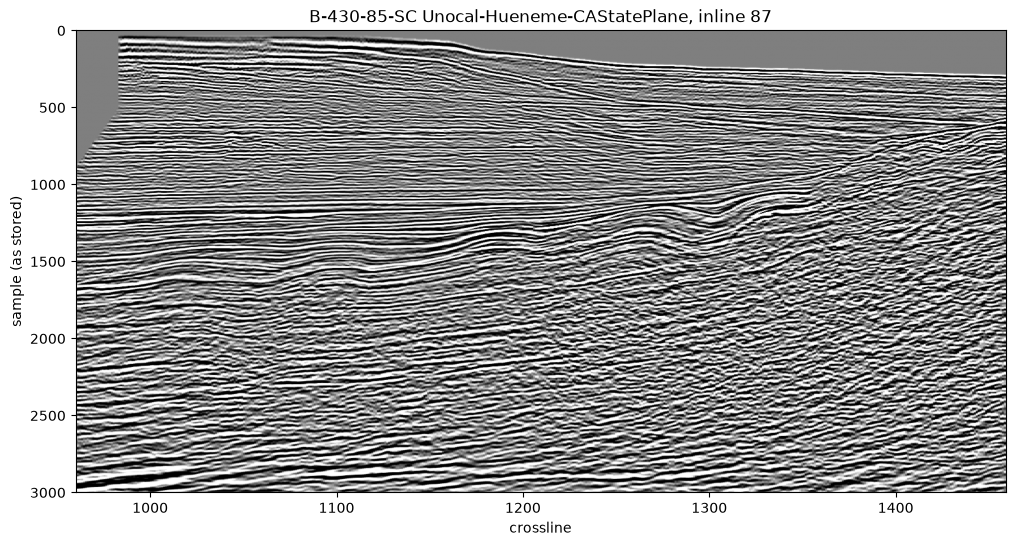

In [15]:
clip = np.percentile(np.abs(section), 99)
fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(section, cmap="gray_r", vmin=-clip, vmax=clip, aspect="auto",
          extent=[xlines[0], xlines[-1], samples[-1], samples[0]])
ax.set_xlabel("crossline")
ax.set_ylabel("sample (as stored)")
ax.set_title(f"{SURVEY} {name}, inline {il}")
plt.show()

Then the sonic log from Hole 504B: P-wave velocity against depth below the seafloor, from the main pass on DSDP Leg 70. Gray dots are the samples (every 10 cm) and the black line is a 3 m running median. The values are as LDEO processed them; spikes above 8 km/s are off the plot.

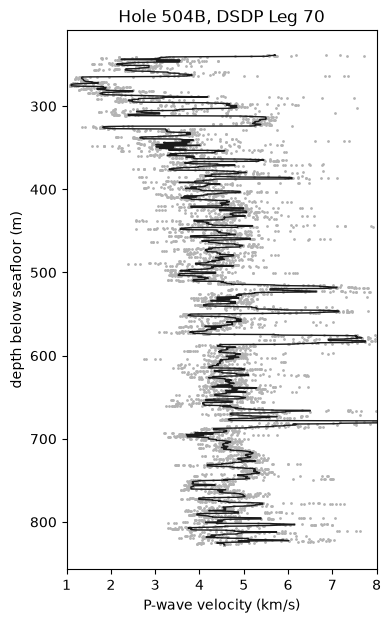

89 of 5893 samples above 8 km/s


In [16]:
median = sonic.VP.rolling(31, center=True, min_periods=1).median()
fig, ax = plt.subplots(figsize=(4, 7))
ax.scatter(sonic.VP, sonic.DEPTH_WMSF, s=1, color="0.7")
ax.plot(median, sonic.DEPTH_WMSF, lw=1, color="0.1")
ax.set_xlim(1, 8)
ax.invert_yaxis()
ax.set_xlabel("P-wave velocity (km/s)")
ax.set_ylabel("depth below seafloor (m)")
ax.set_title("Hole 504B, DSDP Leg 70")
plt.show()
print((sonic.VP > 8).sum(), "of", len(sonic), "samples above 8 km/s")

Next, where the Gulf part of the release sits. Gray lines are every NAMSS 3D survey outline in the index, blue lines the 20 Gulf surveys in release 0.1, and the dots are exploration wells drilled inside those surveys after they were shot (orange: the well discovered at least one sand in BOEM's atlas).

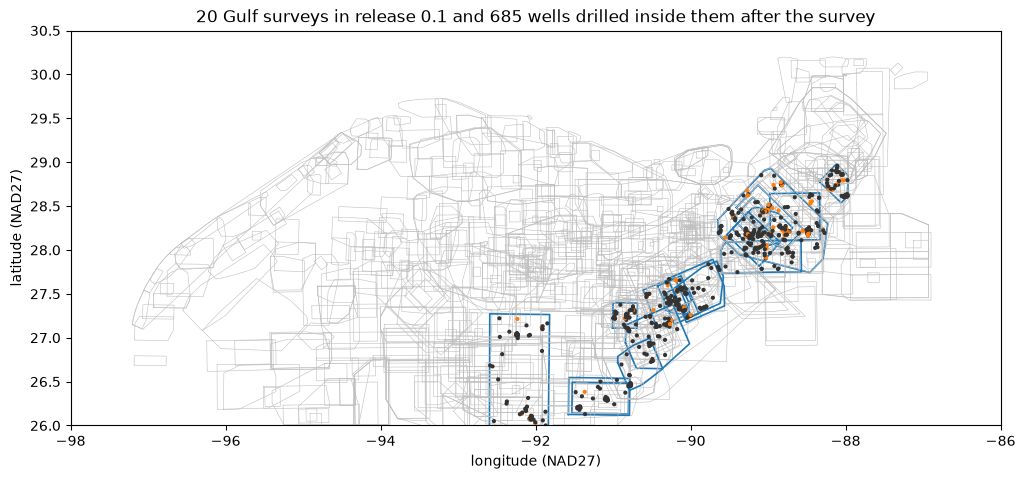

In [17]:
footprints = json.loads(fs.cat(f"{ROOT}/metadata/index/seismic/footprints.geojson"))
wells = read_csv("metadata/index/wells/gulf_exploration_wells.csv", dtype={"api": str}, low_memory=False)
for c in ["bot_lon", "bot_lat", "surf_lon", "surf_lat"]:
    wells[c] = pd.to_numeric(wells[c], errors="coerce")
wells["lon"] = wells.bot_lon.fillna(wells.surf_lon)
wells["lat"] = wells.bot_lat.fillna(wells.surf_lat)

gulf_release = set(release[release.part == "namss-gulf-psdm"].survey_id)
year = volumes.drop_duplicates("survey_id").set_index("survey_id").year
pairs = wells.assign(survey=wells.surveys.str.split(";")).explode("survey")
pairs = pairs[pairs.survey.isin(gulf_release) & (pairs.spud_year > pairs.survey.map(year))]

fig, ax = plt.subplots(figsize=(12, 7))
for feat in footprints["features"]:
    p = feat["properties"]
    if p["source"] != "namss" or p["footprint"] != "NAMSS navigation outline":
        continue
    rings = feat["geometry"]["coordinates"]
    rings = rings if feat["geometry"]["type"] == "Polygon" else [r for poly in rings for r in poly]
    chosen = p["survey_id"] in gulf_release
    for ring in rings:
        xy = np.array(ring)
        ax.plot(xy[:, 0], xy[:, 1], color="tab:blue" if chosen else "0.75", lw=1.2 if chosen else 0.4)
w = pairs.drop_duplicates("api")
ax.scatter(w.lon, w.lat, s=4, color=np.where(w.discovery, "tab:orange", "0.2"), zorder=3)
ax.set_xlim(-98, -86); ax.set_ylim(26, 30.5); ax.set_aspect(1 / np.cos(np.radians(28)))
ax.set_xlabel("longitude (NAD27)"); ax.set_ylabel("latitude (NAD27)")
ax.set_title(f"{len(gulf_release)} Gulf surveys in release 0.1 and {len(w)} wells drilled inside them after the survey")
plt.show()

### Q: What is one question that you have answered using these data? Can you show us how you came to that answer?

How often did an exploration well drilled inside a 3D survey, after the survey was shot, find pay? The wells table answers it for the whole Gulf. A well counts as a discovery when BOEM's sands atlas names it as the discovery well of at least one sand. That makes the rate a lower bound: a well that found pay in a sand someone else had already found counts as a miss.

In [18]:
after = wells[wells.after_survey == True]
summary = after.groupby("setting").discovery.agg(wells="size", discoveries="sum")
summary["rate"] = (summary.discoveries / summary.wells).round(3)
summary.loc["all"] = [len(after), after.discovery.sum(), round(after.discovery.mean(), 3)]
summary

,wells,discoveries,rate
setting,,,
deep,1651,307,0.186
shelf,3244,926,0.285
all,4895,1233,0.252


The same count for each Gulf survey in the release, which is how those surveys were chosen (the most wells drilled after the shoot):

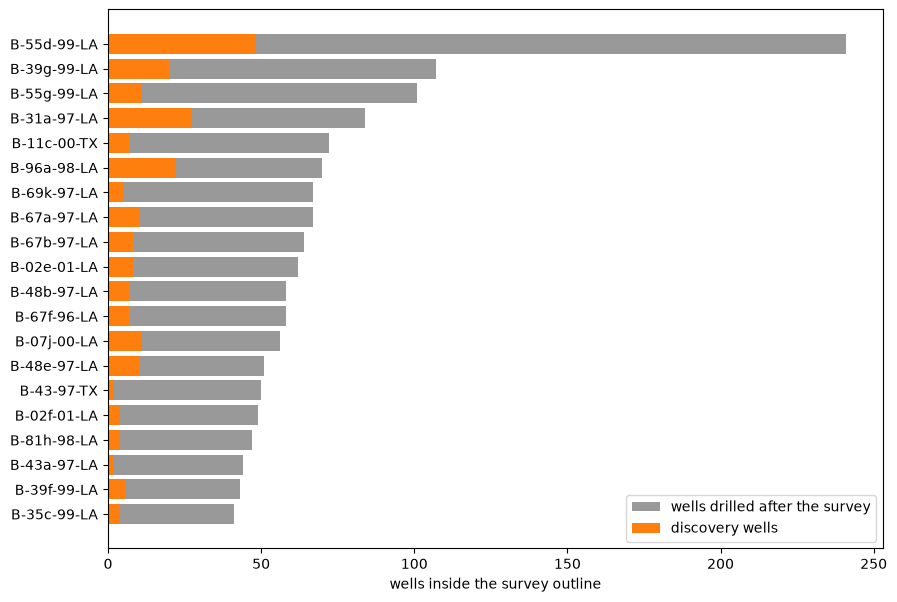

In [19]:
per = pairs.groupby("survey").agg(wells=("api", "nunique"), discoveries=("discovery", "sum"))
per = per.sort_values("wells")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(per.index, per.wells, color="0.6", label="wells drilled after the survey")
ax.barh(per.index, per.discoveries, color="tab:orange", label="discovery wells")
ax.set_xlabel("wells inside the survey outline")
ax.legend(loc="lower right")
plt.show()

### Q: What is one unanswered question that you think could be answered using these data? Do you have any recommendations or advice for someone wanting to answer this question?

Can the seismic around a well, as it looked before the well was drilled, predict whether the well found pay?

The pieces are here. The wells table gives the outcome and the spud date, every Gulf survey in the release was shot before the wells counted against it, and `metadata/index/wells/gulf_well_volume_ties.csv` places wells in the inline and crossline grid of the volumes whose coordinates we could fit. Some advice:

- Use only ties with `grid_quality` of `good`, and check the coordinate system in `seismic/grids.csv`.
- Split training and test data by field or by area. Wells in one field share their seismic and their outcome, so a random split leaks.
- Treat the labels as a lower bound, as above.
- The volumes are depth migrated, so a window around the well's bottom-hole position in inline, crossline and depth is a natural input. A pretrained seismic encoder is a good place to start.

If you try it, tell us: open an issue at https://github.com/mnky9800n/open-subsurface-data/issues.